<a href="https://colab.research.google.com/github/chtzortzi-alt/Tzortzi_Facial_Expressions/blob/main/Tzortzi_Imaging_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q kagglehub

Dataset is hosted on Kaggle. The original one was last updated 6 years ago. I prefer an immediate retrieval than working locally and performing a manual upload every time I work on the assignment.

In [4]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download("msambare/fer2013")
)

print("Dataset location:", dataset_path)
print("Folder contents:", [p.name for p in dataset_path.iterdir()])

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset location: /kaggle/input/fer2013
Folder contents: ['test', 'train']


Represents the dataset's location and specifies the dataset owner and dataset name. Displays the path to stored location and folder contents confirms the code's availability to access the data.

In [5]:
for item in dataset_path.iterdir():
  print(item.name, "- Directory:", item.is_dir())

test - Directory: True
train - Directory: True


Checks the folders' types. The original dataset contains two subsets of train and test. The training one will be further split to an 80% training and a 20% validation subset using a stratification technique to preserve the original distirbution of the seven facial expression categories. The original test set will remain unchanged.

In [6]:
train_path = dataset_path / "train"
test_path = dataset_path / "test"

train_classes = sorted([
    folder.name
    for folder in train_path.iterdir()
    if folder.is_dir()
])

test_classes = sorted([
    folder.name
    for folder in test_path.iterdir()
    if folder.is_dir()
])

print("Training categories:", train_classes)
print("Testing categories:", test_classes)

Training categories: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Testing categories: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


We check the contents of each separate directory (test, train) wanting to find the same seven facial expression categories. These are sorted alphabetically: anger, disgust, fear, happy, neutral, sad and surprise. This is important so as to ensure consistency during the preprocessing, training and evaluation.

In [7]:
from collections import Counter

extensions = Counter(
    file.suffix.lower()
    for folder in train_path.iterdir()
    if folder.is_dir()
    for file in folder.iterdir()
    if file.is_file()
)

print("Training file extensions:", extensions)

Training file extensions: Counter({'.jpg': 28709})


All images are in .jpg format (training set). Total number of images accounting to 28.709.

In [8]:
from PIL import Image
import numpy as np

sample_path = sorted((train_path / "happy").glob("*.jpg"))[0]

with Image.open(sample_path) as img:
  print("Image format:", img.format)
  print("Image mode:", img.mode)
  print("Image dimensions:", img.size)

  pixels = np.array(img)

print("Array shape:", pixels.shape)
print("Pixel data type:", pixels.dtype)
print("Minimum pixel value:", pixels.min())
print("Maximum pixel value:", pixels.max())

Image format: JPEG
Image mode: L
Image dimensions: (48, 48)
Array shape: (48, 48)
Pixel data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


The instance of an inspected image is grayscale. Therefore, it seems that there won't be a need for conversion. Dimensions appear to be 48x48 and the pixel value range is 0-255. The images will be normalized on a 0-1 scale.

In [9]:
import pandas as pd

data = []

for split, path in [("train", train_path), ("test", test_path)]:
  for folder in sorted(path.iterdir()):
    if folder.is_dir():
      image_count = len([
          file for file in folder.iterdir()
          if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
      ])

      data.append({
          "split": split,
          "expression": folder.name,
          "count": image_count
      })

df = pd.DataFrame(data)

display(df)

,split,expression,count
0,train,angry,3995
1,train,disgust,436
2,train,fear,4097
3,train,happy,7215
4,train,neutral,4965
5,train,sad,4830
6,train,surprise,3171
7,test,angry,958
8,test,disgust,111
9,test,fear,1024


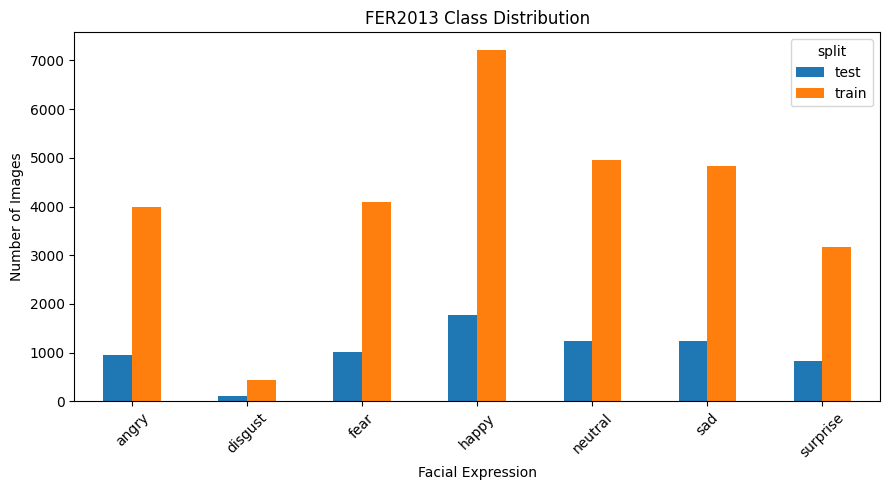

In [10]:
import matplotlib.pyplot as plt

class_counts = df.pivot(
    index = "expression",
    columns = "split",
    values = "count"
)

class_counts.plot(kind = "bar", figsize = (9, 5))

plt.title("FER2013 Class Distribution")
plt.xlabel("Facial Expression")
plt.ylabel("Number of Images")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [11]:
class_percentages = (
    class_counts.div(class_counts.sum(axis = 0), axis = 1) * 100
)

display(class_percentages.round(2))

split,test,train
expression,,
angry,13.35,13.92
disgust,1.55,1.52
fear,14.27,14.27
happy,24.71,25.13
neutral,17.18,17.29
sad,17.37,16.82
surprise,11.58,11.05


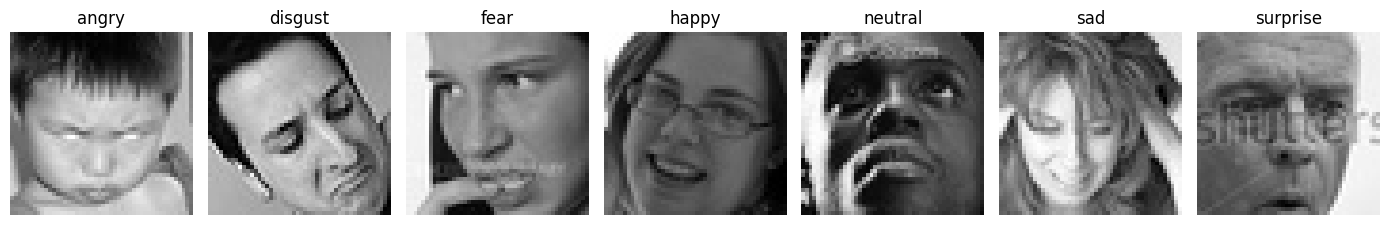

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 7, figsize = (14, 3))

for i, expression in enumerate(train_classes):
  expression_path = train_path / expression

  image_files = sorted(expression_path.glob("*.jpg"))

  image = Image.open(image_files[0])

  axes[i].imshow(image, cmap = "gray")
  axes[i].set_title(expression)
  axes[i].axis("off")

plt.tight_layout()
plt.show()

In [13]:
from PIL import Image
from collections import Counter

image_properties = Counter()
file_extensions = Counter()
corrupted_files = []

for split, path in [("train", train_path), ("test", test_path)]:
  for expression in train_classes:
    folder = path / expression

    for file in sorted(folder.iterdir()):
      if file.is_file():
        file_extensions[(split, file.suffix.lower())] +=1

        try:
          with Image.open(file) as img:
            img.load

            image_properties[
                (split, img.size, img.mode, img.format)
            ] +=1

        except Exception as e:
              corrupted_files.append((str(file), str(e)))

print("File extensions:", file_extensions)
print("Image properties:", image_properties)
print("Unreadable files:", len(corrupted_files))

if corrupted_files:
  print("Examples:", corrupted_files[:5])


File extensions: Counter({('train', '.jpg'): 28709, ('test', '.jpg'): 7178})
Image properties: Counter({('train', (48, 48), 'L', 'JPEG'): 28709, ('test', (48, 48), 'L', 'JPEG'): 7178})
Unreadable files: 0


Moving on to data preprocessing:

In [14]:
image_records = []

for expression in train_classes:
  expression_folder = train_path / expression

  for image_file in sorted(expression_folder.glob("*.jpg")):
    image_records.append({
        "file_path": str(image_file.relative_to(dataset_path)),
        "expression": expression
    })

images_df = pd.DataFrame(image_records)

display(images_df.head())
print("Total training records:", len(images_df))

,file_path,expression
0,train/angry/Training_10118481.jpg,angry
1,train/angry/Training_10120469.jpg,angry
2,train/angry/Training_10131352.jpg,angry
3,train/angry/Training_10161559.jpg,angry
4,train/angry/Training_1021836.jpg,angry


Total training records: 28709


In [15]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    images_df,
    test_size = 0.20,
    random_state = 42,
    stratify = images_df["expression"]
)

train_df = train_df.reset_index(drop = True)
val_df = val_df.reset_index(drop = True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 22967
Validation images: 5742


In [16]:
train_distribution = train_df["expression"].value_counts(
    normalize = True
) * 100

validation_distribution = val_df["expression"].value_counts(
    normalize = True
) * 100

distribution_comparison = pd.DataFrame({
    "Training (%)": train_distribution,
    "Validation (%)": validation_distribution
})

display(distribution_comparison.round(2))

,Training (%),Validation (%)
expression,,
happy,25.13,25.13
neutral,17.29,17.29
sad,16.82,16.82
fear,14.27,14.28
angry,13.92,13.92
surprise,11.05,11.04
disgust,1.52,1.52


In [17]:
from pathlib import Path

output_dir = Path("/content/splits")
output_dir.mkdir(parents = True, exist_ok = True)

train_df.to_csv(output_dir / "train_split.csv", index = False)
val_df.to_csv(output_dir / "validation_split.csv", index = False)

print("Split files saved to:", output_dir)

Split files saved to: /content/splits


In [18]:
print("Saved files:")

for file in output_dir.iterdir():
  print(file.name, "-", file.stat().st_size, "bytes")

Saved files:
train_split.csv - 926618 bytes
validation_split.csv - 231746 bytes


Training and validation split with manual download to computer and upload to GitHub.
locations on GitHub:
train set: https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/train_split.csv
validation set: https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/validation_split.csv

In [19]:
import pandas as pd

train_url = "https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/train_split.csv"
val_url = "https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/validation_split.csv"

train_df = pd.read_csv(train_url)
val_df = pd.read_csv(val_url)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))

overlap = set(train_df["file_path"]) & set(val_df["file_path"])

print("Overlapping image paths:", len(overlap))

Training records: 22967
Validation records: 5742
Overlapping image paths: 0


Image shape: (48, 48)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


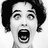

In [20]:
import numpy as np
from PIL import Image

image_path = dataset_path / train_df.iloc[0]["file_path"]

with Image.open(image_path) as img:
  image_array = np.array(img)

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

display(Image.open(image_path))

In [21]:
normalized_image = image_array.astype("float32") / 255.0

print("Original data type:", image_array.dtype)
print("Normalized data type:", normalized_image.dtype)

print("Original pixel range:", image_array.min(), image_array.max())
print("Normalized pixel range:", normalized_image.min(), normalized_image.max())

print("Image shape after normalization:", normalized_image.shape)

Original data type: uint8
Normalized data type: float32
Original pixel range: 0 255
Normalized pixel range: 0.0 1.0
Image shape after normalization: (48, 48)


black corresponds to 0, white corresponds to 1, gray to all in-between values

encoding

In [22]:
label_mapping = {
    expression: i
    for i, expression in enumerate(train_classes)
}

print("Label mapping:", label_mapping)

train_df["label"] = train_df["expression"].map(label_mapping).astype("int32")
val_df["label"] = val_df["expression"].map(label_mapping).astype("int32")

print("Training label type:", train_df["label"].dtype)
print("Validation label type:", val_df["label"].dtype)

display(train_df.head())

Label mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Training label type: int32
Validation label type: int32


,file_path,expression,label
0,train/fear/Training_21644135.jpg,fear,2
1,train/fear/Training_85697399.jpg,fear,2
2,train/angry/Training_80724752.jpg,angry,0
3,train/happy/Training_8750576.jpg,happy,3
4,train/neutral/Training_16088401.jpg,neutral,4


In [23]:
print("Training labels:")
print(sorted(train_df["label"].unique()))
print("Validation labels:")
print(sorted(val_df["label"].unique()))

print("\nMissing training labels:", train_df["label"].isna().sum())
print("Missing validation labels:", val_df["label"].isna().sum())

Training labels:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
Validation labels:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]

Missing training labels: 0
Missing validation labels: 0


In [24]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [25]:
def load_image(file_path, label):
  image = tf.io.read_file(file_path)

  image = tf.image.decode_jpeg(
      image, channels = 1
  )

  image = tf.image.convert_image_dtype(
      image, tf.float32
  )

  label = tf.cast(label, tf.int32)

  return image, label

In [26]:
sample_path = str(
    dataset_path / train_df.iloc[0]["file_path"]
)

sample_label = int(train_df.iloc[0]["label"])

image_tensor, label_tensor = load_image(
    sample_path, sample_label
)

print("Tensor shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)
print("Label data type:", label_tensor.dtype)

print("Minimum pixel value:", float(tf.reduce_min(image_tensor)))
print("Maximum pixel value:", float(tf.reduce_max(image_tensor)))

print("Numerical label:", int(label_tensor.numpy()))
print("Expression:", train_df.iloc[0]["expression"])

Tensor shape: (48, 48, 1)
Tensor data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Numerical label: 2
Expression: fear


In [27]:
combined_df = pd.concat(
    [train_df, val_df],
    ignore_index = True
)

missing_files = []
mismatched_labels = []

for _, row in combined_df.iterrows():
  image_path = dataset_path / row["file_path"]
  if not image_path.is_file():
    missing_files.append(row["file_path"])
  if image_path.parent.name != row["expression"]:
    mismatched_labels.append(row["file_path"])

print("Missing files:", len(missing_files))
print("Mismatched labels", len(mismatched_labels))
print("Total records:", len(combined_df))
print("Unique paths:", combined_df["file_path"].nunique())

Missing files: 0
Mismatched labels 0
Total records: 28709
Unique paths: 28709


In [28]:
import hashlib
from collections import defaultdict

file_hashes = defaultdict(list)

for split_name, dataframe in [
    ("train", train_df), ("validation", val_df)
]:
  for relative_path in dataframe["file_path"]:
    image_path = dataset_path / relative_path

    with open(image_path, "rb") as f:
      image_hash = hashlib.sha256(f.read()).hexdigest()

    file_hashes[image_hash].append(
        (split_name, relative_path)
    )

for expression in test_classes:
  for image_path in sorted((test_path / expression).glob("*.jpg")):

    with open(image_path, "rb") as f:
      image_hash = hashlib.sha256(f.read()).hexdigest()

    file_hashes[image_hash].append(
        ("test", str(image_path.relative_to(dataset_path)))
    )

duplicates = {
    h: records
    for h, records in file_hashes.items()
    if len(records) > 1
}

cross_split_duplicates = {
    h: records
    for h, records in duplicates.items()
    if len({split for split, path in records}) > 1
}

print("Exact duplicate groups:", len(duplicates))
print("Duplicate groups crossing splits:", len(cross_split_duplicates))

if cross_split_duplicates:
  print("\nExamples of cross-split duplicates:")
  for records in list(cross_split_duplicates.values())[:5]:
    print(records)
else:
  print("\nNo byte-identical cross-split duplicates detected.")

Exact duplicate groups: 1516
Duplicate groups crossing splits: 870

Examples of cross-split duplicates:
[('train', 'train/sad/Training_41738651.jpg'), ('test', 'test/sad/PublicTest_69913046.jpg')]
[('train', 'train/fear/Training_33536015.jpg'), ('validation', 'train/fear/Training_44742348.jpg')]
[('train', 'train/fear/Training_32937411.jpg'), ('validation', 'train/fear/Training_87895152.jpg')]
[('train', 'train/sad/Training_48621797.jpg'), ('train', 'train/happy/Training_87607167.jpg'), ('train', 'train/neutral/Training_89335926.jpg'), ('train', 'train/angry/Training_78540321.jpg'), ('train', 'train/angry/Training_96772745.jpg'), ('train', 'train/angry/Training_32571770.jpg'), ('train', 'train/angry/Training_99531165.jpg'), ('train', 'train/angry/Training_28756096.jpg'), ('train', 'train/angry/Training_52563817.jpg'), ('train', 'train/angry/Training_10131352.jpg'), ('validation', 'train/surprise/Training_48403842.jpg'), ('test', 'test/angry/PublicTest_5543497.jpg')]
[('train', 'train/s

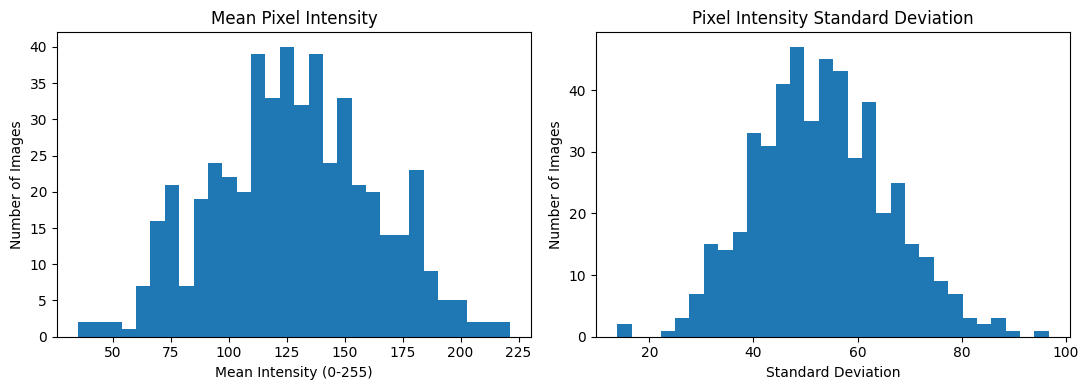

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_df = train_df.sample(n=500, random_state=42)

mean_intensities = []
std_intensities = []

for relative_path in sample_df["file_path"]:
  image_path = dataset_path / relative_path

  with Image.open(image_path) as img:
    pixels = np.array(img, dtype = np.float32)

  mean_intensities.append(pixels.mean())
  std_intensities.append(pixels.std())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(mean_intensities, bins=30)
axes[0].set_title("Mean Pixel Intensity")
axes[0].set_xlabel("Mean Intensity (0-255)")
axes[0].set_ylabel("Number of Images")

axes[1].hist(std_intensities, bins=30)
axes[1].set_title("Pixel Intensity Standard Deviation")
axes[1].set_xlabel("Standard Deviation")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [30]:
all_labels = {}

for dataframe in [train_df, val_df]:
  all_labels.update(
      dict(zip(dataframe["file_path"], dataframe["expression"]))
  )

for expression in test_classes:
  for path in (test_path / expression).glob("*.jpg"):
    relative_path = str(path.relative_to(dataset_path))
    all_labels[relative_path] = expression

duplicate_file_count = sum(
    len(records) for records in duplicates.values()
)

cross_split_file_count = sum(
    len(records) for records in cross_split_duplicates.values()
)

conflicting_groups = {}

for image_hash, records in duplicates.items():
  labels = {
      all_labels[path]
      for split, path in records
  }
  if len(labels) > 1:
    conflicting_groups[image_hash] = records

train_test_groups = {
    h: records
    for h, records in duplicates.items()
    if "test" in {split for split, path in records}
    and any(split in {"train", "validation"} for split, path in records)
}

print("Files belonging to duplicate groups:", duplicate_file_count)
print("Files in cross-split duplicate groups:", cross_split_file_count)
print("Groups with conflicting expression labels:", len(conflicting_groups))
print("Groups shared with the original test set:", len(train_test_groups))

print("\n Largest duplicate group size:", max(len(records) for records in duplicates.values()))


Files belonging to duplicate groups: 3369
Files in cross-split duplicate groups: 2025
Groups with conflicting expression labels: 57
Groups shared with the original test set: 531

 Largest duplicate group size: 12


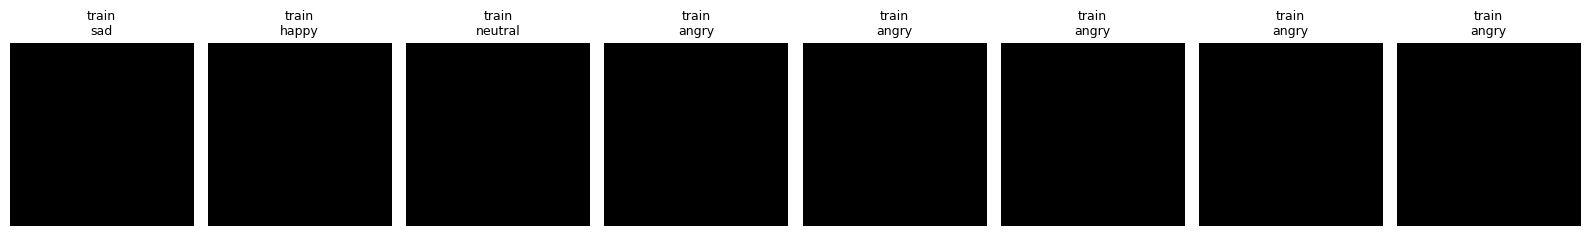

In [31]:
import matplotlib.pyplot as plt
from PIL import Image

example_records = max(
    conflicting_groups.values(), key = len
)

n = min(len(example_records), 8)

fig, axes = plt.subplots(1, n, figsize=(2*n, 3))

if n == 1:
  axes = [axes]

for ax, (split, relative_path) in zip(axes, example_records[:n]):
  image_path = dataset_path / relative_path

  with Image.open(image_path) as img:
    ax.imshow(img, cmap="gray")

  ax.set_title(
      f"{split}\n{all_labels[relative_path]}", fontsize=9
    )
  ax.axis("off")

plt.tight_layout()
plt.show()

In [34]:
import numpy as np
import pandas as pd
from PIL import Image

image_quality_records = []

for image_path in sorted(dataset_path.rglob("*.jpg")):
  with Image.open(image_path) as img:
    pixels = np.asarray(img, dtype=np.float32)

  relative_path = image_path.relative_to(dataset_path)

  image_quality_records.append({
    "file_path": str(relative_path), "split": relative_path.parts[0],
    "expression": image_path.parent.name, "min_intensity": pixels.min(), "max_intensity": pixels.max(),
    "intensity_range": np.ptp(pixels), "std_intensity": pixels.std()
  })

quality_df = pd.DataFrame(image_quality_records)

constant_images = quality_df[
    quality_df["intensity_range"] == 0
]

low_variation_images = quality_df[
    (quality_df["intensity_range"] > 0) &
    (quality_df["std_intensity"] < 5)
]

print("Total images checked:", len(quality_df))
print("Images checked by original split:", quality_df["split"].value_counts())
print("\nconstant-intensity images:", len(constant_images))
print("Low-variation images (std < 5):", len(low_variation_images))

print("\nConstant images by  split:", constant_images["split"].value_counts())
print("Constant images by expression:", constant_images["expression"].value_counts())

print("\nConstant image examples:")
print(
    constant_images[
        ["file_path", "expression", "min_intensity", "max_intensity"]
    ].head(15).to_string(index = False)
)

assert len(quality_df) == 35887
assert (quality_df["split"] == "train").sum() == (28709)
assert (quality_df["split"] == "test").sum() == (7178)

Total images checked: 35887
Images checked by original split: split
train    28709
test      7178
Name: count, dtype: int64

constant-intensity images: 12
Low-variation images (std < 5): 2

Constant images by  split: split
train    11
test      1
Name: count, dtype: int64
Constant images by expression: expression
angry       8
happy       1
neutral     1
sad         1
surprise    1
Name: count, dtype: int64

Constant image examples:
                           file_path expression  min_intensity  max_intensity
   test/angry/PublicTest_5543497.jpg      angry            0.0            0.0
   train/angry/Training_10131352.jpg      angry            0.0            0.0
   train/angry/Training_28756096.jpg      angry            0.0            0.0
   train/angry/Training_32571770.jpg      angry            0.0            0.0
   train/angry/Training_52563817.jpg      angry            0.0            0.0
   train/angry/Training_78540321.jpg      angry            0.0            0.0
   train/angry/Tr

In [35]:
example_records = max(
    conflicting_groups.values(), key = len
)

split, relative_path = example_records[0]
image_path = dataset_path / relative_path

with Image.open(image_path) as img:
  pixels = np.asarray(img)

print("Image:", relative_path)
print("Minimum intensity:", pixels.min())
print("Maximum intensity:", pixels.max())
print("Standard deviation:", pixels.std())
print("Unique pixel values:", np.unique(pixels))

Image: train/sad/Training_48621797.jpg
Minimum intensity: 0
Maximum intensity: 0
Standard deviation: 0.0
Unique pixel values: [0]


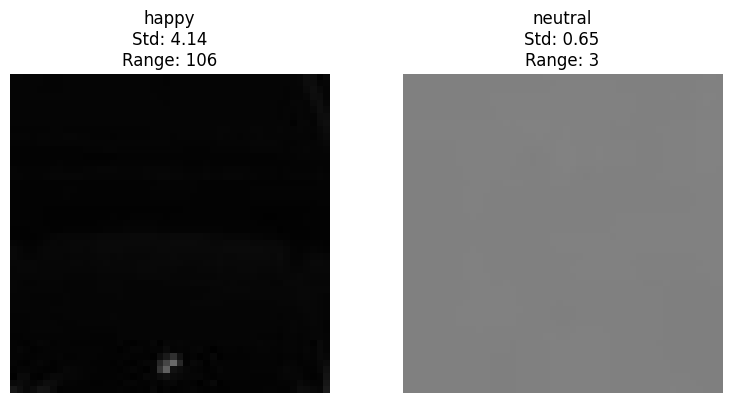

In [42]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

n = len(low_variation_images)

fig, axes = plt.subplots(1, n, figsize=(4*n, 4))

axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, low_variation_images.iterrows()):
  image_path = dataset_path / row["file_path"]

  with Image.open(image_path) as img:
    pixels = np.asarray(img)

  ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)

  ax.set_title(
      f"{row['expression']}\n"
      f"Std: {row['std_intensity']:.2f}\n"
      f"Range: {row['intensity_range']:.0f}"
  )

  ax.axis("off")

plt.tight_layout()
plt.show()

In [44]:
thresholds = [5, 10, 15, 20, 25, 30]

for threshold in thresholds:
  count = (
      (quality_df["std_intensity"] < threshold) & (quality_df["intensity_range"] > 0)
  ).sum()

  print(f"Std < {threshold}: {count} images")

Std < 5: 2 images
Std < 10: 3 images
Std < 15: 7 images
Std < 20: 84 images
Std < 25: 351 images
Std < 30: 1081 images


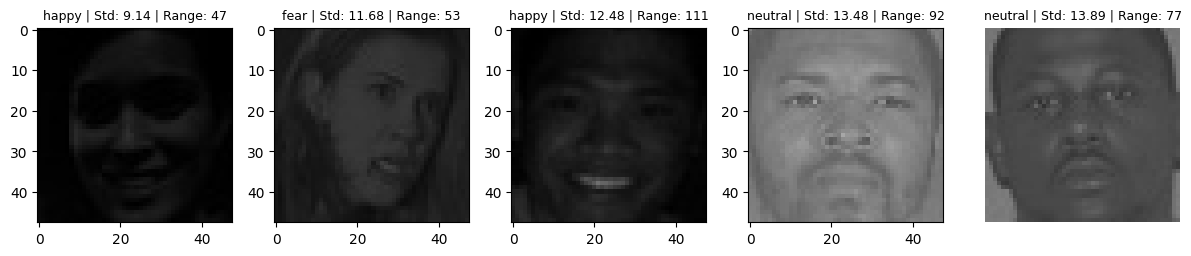

In [49]:
candidate_images = quality_df[
    (quality_df["std_intensity"] >= 5) & (quality_df["std_intensity"] < 15)
].sort_values("std_intensity")

n = min(len(candidate_images), 20)

if n == 0:
  print("No images found in this range")

else:
  fig, axes = plt.subplots(
      nrows=(n+4)//5, ncols=5, figsize=(12, 3*((n+4)//5))
  )

  axes = np.asarray(axes).flatten()

  for ax, (_, row) in zip(axes, candidate_images.head(n).iterrows()):
    image_path = dataset_path / row["file_path"]

    with Image.open(image_path) as img:
      pixels = np.asarray(img)

    ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)

    ax.set_title(
      f"{row['expression']} | Std: {row['std_intensity']:.2f} | Range: {row['intensity_range']:.0f}",
      fontsize=9
  )

  ax.axis("off")

for ax in axes[n:]:
  ax.axis("off")

plt.tight_layout()
plt.show()

decision to exclude all images with 0 <= std < 5

In [50]:
clean_df = quality_df.loc[
    quality_df["split"] == "train", ["file_path", "expression"]
].copy()

print("Original training images:", len(clean_df))

hash_lookup = {
    path: image_hash
    for image_hash, records in file_hashes.items()
    for split, path in records
}

clean_df["hash"] = clean_df["file_path"].map(hash_lookup)

assert clean_df["hash"].notna().all()

# constant intensity images (min=max) and images with std < 5
unusable_paths = set(
    quality_df.loc[
        (quality_df["intensity_range"] == 0) |
        (
            (quality_df["intensity_range"] > 0) &
            (quality_df["std_intensity"] < 5)
        ),
        "file_path"
    ]
)

before = len(clean_df)
clean_df = clean_df[
    ~clean_df["file_path"].isin(unusable_paths)
].copy()

print("Removed unusable images:", before - len(clean_df))

# groups with conflicting labels
conflicting_hashes = set(conflicting_groups.keys())

before = len(clean_df)
clean_df = clean_df[
    ~clean_df["hash"].isin(conflicting_hashes)
].copy()

print("Removed conflicting-label recordings:", before - len(clean_df))

# images identical to original test set images
test_hashes = {
    image_hash
    for image_hash, records in file_hashes.items()
    if any(split == "test" for split, path in records)
}

before = len(clean_df)
clean_df = clean_df[
    ~clean_df["hash"].isin(test_hashes)
].copy()

print("Removed test-overlapping records:", before - len(clean_df))

# keep one copy per remaining hash
before = len(clean_df)

clean_df = (
    clean_df
    .sort_values("file_path")
    .drop_duplicates(subset="hash", keep="first")
    .reset_index(drop=True)
)

print("Removed remaining duplicate copies:", before - len(clean_df))
print("Final cleaned training pool:", len(clean_df))
print("Class distribution:", clean_df["expression"].value_counts())

assert clean_df["hash"].is_unique
assert not set(clean_df["hash"]) & test_hashes

Original training images: 28709
Removed unusable images: 12
Removed conflicting-label recordings: 116
Removed test-overlapping records: 649
Removed remaining duplicate copies: 1021
Final cleaned training pool: 26911
Class distribution: expression
happy       7030
neutral     4821
sad         4677
fear        3797
angry       3776
surprise    2460
disgust      350
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import train_test_split

train_clean_df, val_clean_df = train_test_split(
    clean_df, test_size=0.20, random_state=42, stratify=clean_df["expression"]
)

train_clean_df = train_clean_df.reset_index(drop=True)
val_clean_df = val_clean_df.reset_index(drop=True)

print("Cleaned training images:", len(train_clean_df))
print("Cleaned validation images:", len(val_clean_df))

assert not (
    set(train_clean_df["hash"]) & set(val_clean_df["hash"])
)

Cleaned training images: 21528
Cleaned validation images: 5383


In [53]:
print("Training class distribution:", train_clean_df["expression"].value_counts())
print("Validation class distribution:", val_clean_df["expression"].value_counts())

assert train_clean_df["file_path"].is_unique
assert val_clean_df["file_path"].is_unique
assert train_clean_df["hash"].is_unique
assert val_clean_df["hash"].is_unique

assert not (
    set(train_clean_df["hash"]) & set(val_clean_df["hash"])
)

assert not (
    set(train_clean_df["hash"]) | set(val_clean_df["hash"])
) & test_hashes

print("All cleaned-split integrity checks passed.")

Training class distribution: expression
happy       5624
neutral     3857
sad         3741
fear        3037
angry       3021
surprise    1968
disgust      280
Name: count, dtype: int64
Validation class distribution: expression
happy       1406
neutral      964
sad          936
fear         760
angry        755
surprise     492
disgust       70
Name: count, dtype: int64
All cleaned-split integrity checks passed.


In [54]:
from pathlib import Path

output_dir = Path("/content/cleaned_splits")
output_dir.mkdir(parents = True, exist_ok = True)

train_clean_df[["file_path", "expression"]].to_csv(output_dir / "train_clean_split.csv", index = False)
val_clean_df[["file_path", "expression"]].to_csv(output_dir / "validation_clean_split.csv", index = False)

print("Clean split files saved to:", output_dir / "train_clean_split.csv", output_dir / "validation_clean_split.csv")

Clean split files saved to: /content/cleaned_splits/train_clean_split.csv /content/cleaned_splits/validation_clean_split.csv
